# Pileup-Dependent Threshold Calibration ($T(\mu) = a\mu + b$)

This notebook implements the standard ATLAS egamma / NeuralRinger pileup threshold correction methodology:
1. **Continuous Discriminant Extraction**: Extract pre-sigmoid continuous outputs ($y_{\text{NN}}$ logits) from the trained neural network.
2. **Signal Slicing in $\langle\mu\rangle$**: Project signal events ($y_{\text{true}} = 1$) into 1D slices across average interactions per crossing $\langle\mu\rangle$.
3. **Slice Threshold Quantiles**: For each $\langle\mu\rangle$ slice, determine the threshold $T_i$ yielding the target Detection Probability ($P_D$) for configured working points (Tight 80%, Medium 90%, Loose 95%, Baseline 94.24%).
4. **Linear Fit**: Fit linear parameters $T(\mu) = a\mu + b$ across the slices.
5. **2D Calibration Visualization**: Display the 2D $(\mu, y_{\text{NN}})$ density heatmap overlaid with slice threshold points and linear fit lines using ATLAS styling.
6. **Holdout Validation & Flatness Verification**: Apply the dynamic boundary $y_{\text{NN}} \ge a\mu + b$ to independent test holdout data and verify that signal efficiency remains flat across $\langle\mu\rangle$.


In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Resolve repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt
import mplhep as mh

mh.style.use("ATLAS")

from src.Parser.NeuralRingerTrainerConfiguration import NeuralRingerTrainerConfiguration
from src.core.Trainers.NeuralRingerTrainer import NeuralRingerTrainer
from src.core.Datasets.SplitManifest import SplitManifest
from src.core.Validation.ResultAggregator import ResultAggregator
from src.core.Validation.HoldoutEvaluator import HoldoutEvaluator
from src.core.Validation.PileupAnalyzer import PileupAnalyzer
from src.core.Validation.PileupThresholdCalibrator import (
    PileupThresholdCalibrator,
    OperatingPointCalibration,
)
from src.core.Plotting.PileupPlotter import PileupPlotter
from src.utils import get_et_eta

print(f"Project root: {PROJECT_ROOT}")
print(f"PyTorch version: {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


Project root: /eos/home-i04/p/pmourafr/egamma_master
PyTorch version: 2.10.0, CUDA available: True


### Centralized Configuration
Specify the target kinematic region, paths to the training configuration, results directory, and target operating points.

In [2]:
# Target Kinematic Region
TARGET_ET: int = 1
TARGET_ETA: int = 1
REGION_KEY: str = f"et_{TARGET_ET}_eta_{TARGET_ETA}"

# Model & Results Paths
CONFIG_PATH: Path = PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml"
RESULTS_PATH: Path = PROJECT_ROOT / "results/config_nameModelV9_HighBatch_100Rings_id20261029001623"
DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = RESULTS_PATH.parent / "split_manifest.json"

# Working Points to Calibrate (Target PDs)
WORKING_POINTS = {
    "Tight": 0.80,
    "Medium": 0.90,
    "Loose": 0.95,
    "Baseline": 0.9424,
}

BINS_MU: int = 10
N_BOOTSTRAPS: int = 100
PLOT_FORMAT: str = "png"

# Output directories
OUTPUT_DIR: Path = PROJECT_ROOT / "notebooks" / f"PileupCalibration_{RESULTS_PATH.name}_{REGION_KEY}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Target Region: {REGION_KEY}")
print(f"Configuration: {CONFIG_PATH}")
print(f"Results Path:  {RESULTS_PATH}")
print(f"Output Dir:    {OUTPUT_DIR}")


Target Region: et_1_eta_1
Configuration: /eos/home-i04/p/pmourafr/egamma_master/config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml
Results Path:  /eos/home-i04/p/pmourafr/egamma_master/results/config_nameModelV9_HighBatch_100Rings_id20261029001623
Output Dir:    /eos/home-i04/p/pmourafr/egamma_master/notebooks/PileupCalibration_config_nameModelV9_HighBatch_100Rings_id20261029001623_et_1_eta_1


### 1. Model Checkpoint Loading & Trainer Initialization
Initialize trainer configuration and extract the top-performing fold model using `ResultAggregator`.

In [3]:
with open(CONFIG_PATH, "r") as f:
    config_dict = yaml.safe_load(f)

if DATA_PATH.exists():
    config_dict["dataset"]["parameters"]["drive_path"] = str(DATA_PATH)

config = NeuralRingerTrainerConfiguration.model_validate(config_dict)
trainer = NeuralRingerTrainer(config)
full_dataset = trainer.full_dataset
feature_names = full_dataset.feature_names

# Aggregate results to select best model
aggregator = ResultAggregator(RESULTS_PATH)
if not aggregator.has_region(TARGET_ET, TARGET_ETA):
    raise RuntimeError(f"No result records found in {RESULTS_PATH} for iet{TARGET_ET}.ieta{TARGET_ETA}")

best_model_dict, best_rep, mean_sp, std_sp = aggregator.get_best_model_for_region(TARGET_ET, TARGET_ETA)
best_fold = int(best_model_dict.get("fold", 0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = trainer.factory.create_model()
model.load_state_dict(best_model_dict["best_weights"])
model.to(device)
model.eval()

print(f"Loaded Best Model (Fold {best_fold}, Rep/Init {best_rep}) for region {REGION_KEY}")
print(f"Model Best SP: {best_model_dict.get('best_sp_value', 0.0):.4f} (Region Mean: {mean_sp:.4f} +/- {std_sp:.4f})")


Loaded Best Model (Fold 6, Rep/Init 3) for region et_1_eta_1
Model Best SP: 0.8464 (Region Mean: 0.8423 +/- 0.0039)


### 2. Dataset Loading & Partitioning
Load calorimeter ring features and metadata, then retrieve the exact train, validation, and holdout test partitions via `SplitManifest`.

In [4]:
# Locate target kinematic region file
region_file_idx = None
for idx, path_str in enumerate(full_dataset.file_paths):
    iet, ieta = get_et_eta(path_str)
    if iet == TARGET_ET and ieta == TARGET_ETA:
        region_file_idx = idx
        break

if region_file_idx is None:
    raise FileNotFoundError(f"No dataset file matching ET={TARGET_ET}, ETA={TARGET_ETA} found.")

raw_features, raw_labels, region_path = full_dataset[region_file_idx]

# Determine ring column indices
ring_indices = getattr(full_dataset, "ring_column_indices", None)
if ring_indices is None:
    ring_indices = getattr(full_dataset, "indexes", None)
if ring_indices is None:
    ring_indices = np.array([
        i for i, name in enumerate(feature_names)
        if name.startswith("ring_") or name.startswith("trig_L2_calo_rings_")
    ])

# Load partitions from SplitManifest
manifest = SplitManifest(str(MANIFEST_PATH))
manifest.load()
test_indices, cv_splits = manifest.get_region_splits(REGION_KEY)
train_indices, val_indices = cv_splits[best_fold]
calib_indices = np.concatenate([train_indices, val_indices])

# Extract partition arrays
calib_features = raw_features[calib_indices]
calib_labels = raw_labels[calib_indices]
test_features = raw_features[test_indices]
test_labels = raw_labels[test_indices]

mu_calib = PileupAnalyzer.extract_feature(calib_features, feature_names, "avgmu")
mu_test = PileupAnalyzer.extract_feature(test_features, feature_names, "avgmu")

print(f"Region Data:  {Path(region_path).name}")
print(f"Calib events: {len(calib_labels):,} (Signal: {np.sum(calib_labels == 1):,}, BG: {np.sum(calib_labels == 0):,})")
print(f"Test events:  {len(test_labels):,} (Signal: {np.sum(test_labels == 1):,}, BG: {np.sum(test_labels == 0):,})")


Region Data:  consolidated.et1.eta1.npz
Calib events: 129,402 (Signal: 35,938, BG: 93,464)
Test events:  14,378 (Signal: 3,994, BG: 10,384)


### 3. Logit Extraction & Signal Selection
Extract pre-sigmoid neural discriminant outputs ($y_{\text{NN}}$) and isolate true signal events ($y_{\text{true}} = 1$) for calibration.

In [5]:
calib_ring_features = calib_features[:, ring_indices]
test_ring_features = test_features[:, ring_indices]

logits_calib = HoldoutEvaluator.predict_logits(model, calib_ring_features, device)
logits_test = HoldoutEvaluator.predict_logits(model, test_ring_features, device)

signal_calib_mask = calib_labels == 1
mu_signal_calib = mu_calib[signal_calib_mask]
logits_signal_calib = logits_calib[signal_calib_mask]

print(f"Calibrating on {len(logits_signal_calib):,} signal events across <mu> in [{mu_signal_calib.min():.1f}, {mu_signal_calib.max():.1f}]")


Calibrating on 35,938 signal events across <mu> in [9.5, 90.5]


### 4. 2D Distribution & Slice Quantile Calibration
Compute 2D histogram grid and perform slice quantile extraction and linear fitting for each working point.

In [6]:
calibrator = PileupThresholdCalibrator(
    bins_mu=BINS_MU,
    n_bootstraps=N_BOOTSTRAPS,
    random_seed=42,
)

dist_2d = calibrator.compute_2d_distribution(mu_signal_calib, logits_signal_calib, bins=35)
calibrations = calibrator.calibrate_multiple_points(mu_signal_calib, logits_signal_calib, WORKING_POINTS)

summary_rows = []
for wp_name, cal in calibrations.items():
    sign = "+" if cal.intercept >= 0 else "-"
    summary_rows.append({
        "Working Point": wp_name,
        "Target PD (%)": f"{cal.target_pd * 100:.2f}%",
        "Slope (a)": f"{cal.slope:.4f}",
        "Intercept (b)": f"{cal.intercept:.4f}",
        "R^2": f"{cal.r_squared:.4f}",
        "Fit Formula": f"T(mu) = {cal.slope:.4f}*mu {sign} {abs(cal.intercept):.4f}",
    })

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(OUTPUT_DIR / "pileup_correction_parameters.csv", index=False)
df_summary


,Working Point,Target PD (%),Slope (a),Intercept (b),R^2,Fit Formula
0,Tight,80.00%,-0.0031,-0.8206,0.3528,T(mu) = -0.0031*mu - 0.8206
1,Medium,90.00%,-0.0006,-1.9734,0.0516,T(mu) = -0.0006*mu - 1.9734
2,Loose,95.00%,-0.0015,-2.5890,0.0643,T(mu) = -0.0015*mu - 2.5890
3,Baseline,94.24%,-0.0008,-2.4866,0.0227,T(mu) = -0.0008*mu - 2.4866


### 5. 2D Calibration Visualization
Plot the 2D $(\mu, y_{\text{NN}})$ density heatmap overlaid with slice threshold points and linear fit lines.

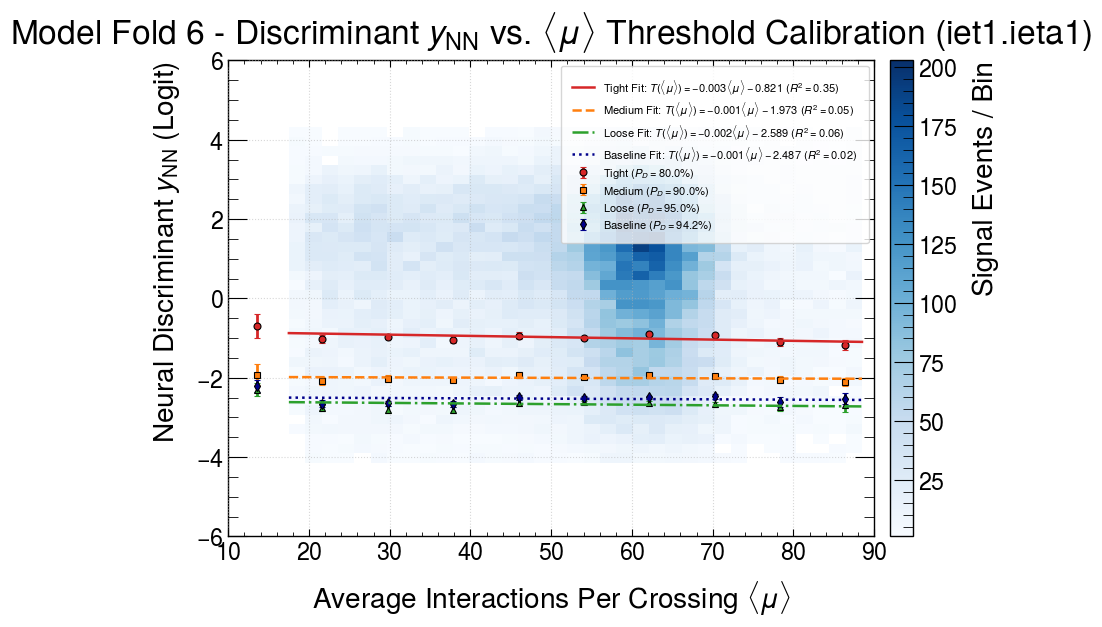

In [7]:
plotter = PileupPlotter()
fig_calib = plotter.plot_2d_threshold_calibration(
    distribution=dist_2d,
    calibrations=list(calibrations.values()),
    title=f"Model Fold {best_fold}",
    region_label=f"iet{TARGET_ET}.ieta{TARGET_ETA}",
    output_path=OUTPUT_DIR / f"pileup_2d_threshold_calibration.{PLOT_FORMAT}",
    file_format=PLOT_FORMAT,
)
plt.show()


### 6. Holdout Test Verification (Flatness Check)
Apply the calibrated dynamic threshold $T(\mu) = a\mu + b$ to independent holdout test data and compare against the static uncorrected threshold to verify efficiency flatness.

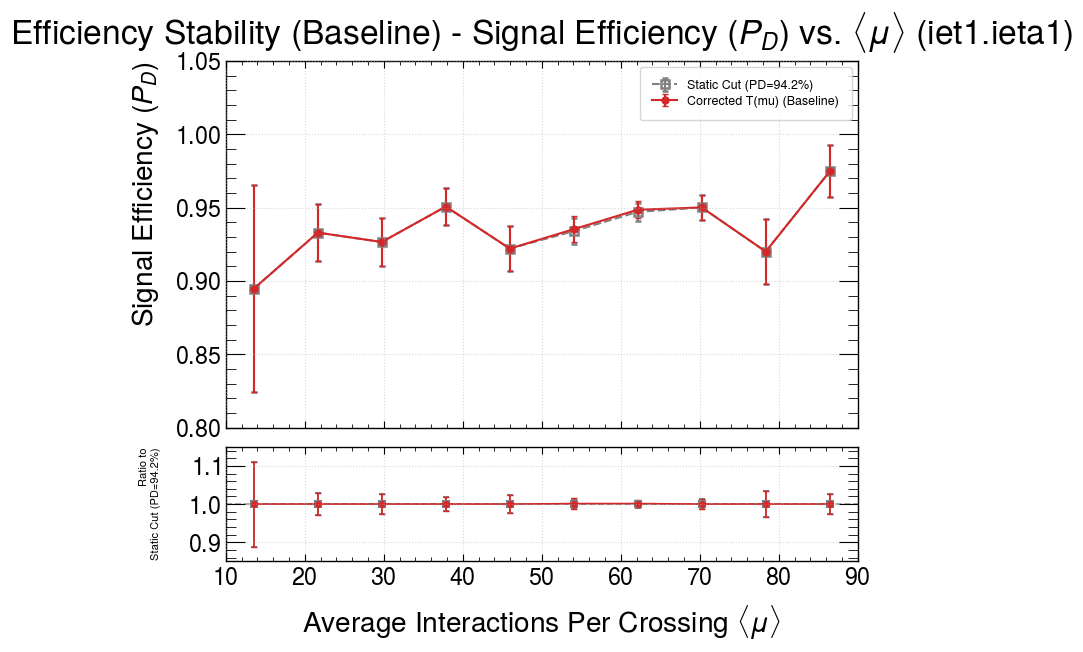

Pileup calibration and validation complete. Figures exported to: /eos/home-i04/p/pmourafr/egamma_master/notebooks/PileupCalibration_config_nameModelV9_HighBatch_100Rings_id20261029001623_et_1_eta_1


In [9]:
# Compare for Tight (80%)
eval_wp = "Baseline"
cal = calibrations[eval_wp]

# 1. Uncorrected static threshold
static_thresh = np.quantile(logits_calib[signal_calib_mask], 1.0 - cal.target_pd)
preds_static = (logits_test >= static_thresh).astype(int)

# 2. Pileup-corrected dynamic threshold
preds_corrected = PileupThresholdCalibrator.apply_threshold(
    logits_test, mu_test, cal.slope, cal.intercept
)

eff_static = PileupAnalyzer.compute_efficiency_vs_mu(mu_test, test_labels, preds_static, bins=10, is_signal=True)
eff_corr = PileupAnalyzer.compute_efficiency_vs_mu(mu_test, test_labels, preds_corrected, bins=10, is_signal=True)

models_comparison = [
    {
        "label": f"Static Cut (PD={cal.target_pd*100:.1f}%)",
        "bin_centers": eff_static["bin_centers"],
        "efficiencies": eff_static["efficiencies"],
        "uncertainties": eff_static["uncertainties"],
        "color": "gray",
        "marker": "s",
        "is_ml": False,
        "is_reference": True,
    },
    {
        "label": f"Corrected T(mu) ({eval_wp})",
        "bin_centers": eff_corr["bin_centers"],
        "efficiencies": eff_corr["efficiencies"],
        "uncertainties": eff_corr["uncertainties"],
        "color": "tab:red",
        "marker": "o",
        "is_ml": True,
        "is_reference": False,
    },
]

fig_eff = plotter.plot_efficiency_vs_mu(
    models_data=models_comparison,
    title=f"Efficiency Stability ({eval_wp})",
    region_label=f"iet{TARGET_ET}.ieta{TARGET_ETA}",
    is_signal=True,
    output_path=OUTPUT_DIR / f"efficiency_vs_mu_corrected_{eval_wp}.{PLOT_FORMAT}",
    file_format=PLOT_FORMAT,
)
plt.show()

print(f"Pileup calibration and validation complete. Figures exported to: {OUTPUT_DIR}")
